<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200"/>
</p></center>

<center><font size=10>Artificial Intelligence and Machine Learning</center></font>
<center><font size=6>Deploying AI solutions: Week 2 - Deploying GenAI solutions</center></font>

<center><p float="center">
  <img src="https://t3.ftcdn.net/jpg/03/91/01/80/240_F_391018013_1v95r7mvj3StoQttQYgPElCxb4nvCAh3.jpg" alt="salesforce-crm-qna" width="640"/>
</p></center>
<center><font size=6>NovaCrest QnA</center></font>

**NOTE:** Several steps in this notebook, including document extraction, vector database creation, and evaluation, may take approximately **20 to 40 minutes** to complete when running on a CPU runtime. Using a **T4 GPU runtime** can significantly reduce the execution time to approximately **5 to 10 minutes**. For optimal performance, it is **recommended to run this notebook with a T4 GPU runtime**.


In this case study, we will build a **Retrieval-Augmented Generation (RAG)** system using Salesforce CRM manuals as the knowledge source. Before we start building the RAG system, it is important to understand what Salesforce CRM is.

## What is Salesforce CRM?

Salesforce CRM is a cloud-based **Customer Relationship Management (CRM) platform** that helps businesses manage customer relationships and interactions.

It provides tools to manage **leads, opportunities, sales activities, customer service, marketing, and customer data** in one platform.

Salesforce also supports **workflow automation, reporting, analytics, and AI-powered features** to help businesses improve productivity and make data-driven decisions.

# Problem Statement

## Business Context

NovaCrest Solutions is a mid-sized B2B SaaS company with a 95-person sales organization spread across 4 regional offices in the USA, onboarding 10 to 12 new sales reps per quarter as the team scales.

Sales reps, sales managers, and Salesforce administrators collectively handle around 550 internal queries per week about Salesforce CRM features, Einstein AI capabilities, lead and opportunity scoring, forecasting setup, edition-specific feature availability, activity capture configuration, customer experience analytics dashboards, licensing, identity verification, navigation, and Data Cloud integration.

Straightforward queries like how to log in or where to find a specific setting can be answered from existing Salesforce documentation. However, roughly 40% of queries are complex and require information pulled from multiple documents such as the Get Started with Salesforce guide, Sales Cloud Einstein documentation, and Customer Experience Intelligence setup guides. Manually cross-referencing these sources takes 8 to 12 minutes per query and results in a 15 to 20% error rate because answers end up incomplete, reference the wrong edition, or miss prerequisite configuration steps.

As the company adopts new Salesforce capabilities like Einstein Generative AI for Sales, CRM Analytics dashboards, agent actions for customer experience intelligence, and Data Cloud integrations, the volume of documentation and edition-specific nuances keeps growing. With roughly 30% annual turnover among sales reps and a 5 to 6 week ramp period for new hires, institutional knowledge about Salesforce configuration, Einstein scoring models, and analytics setup is constantly walking out the door.


## Key Risks

- **Faithfulness**: Avoid unsupported information, for example stating that a feature is available in Professional Edition when it actually requires Performance or Unlimited Edition.
- **Retrieval completeness**: Retrieve all relevant information, for example pulling both the Einstein Lead Scoring setup steps and the data requirements that affect scoring accuracy.
- **Retrieval precision**: Retrieve relevant source chunks, for example returning Sales Cloud Einstein documentation rather than unrelated Service Cloud content when a rep asks about opportunity scoring.
- **Answer relevancy**: Directly answer the user's question, for example when asked "How does Einstein score my leads?", explain the machine learning model and scoring factors rather than returning generic Einstein marketing copy.

A RAG system can retrieve the relevant information from Salesforce documentation and help internal teams get accurate, source-grounded answers without relying on tribal knowledge or waiting for an admin to respond.

## Objective

The objective is to build a POC for an internal-facing application where sales reps, managers, and Salesforce admins at NovaCrest can type in natural-language questions and receive answers grounded in the company's Salesforce documentation library.

The application should:

- Provide a simple UI where users can enter their questions about Salesforce CRM features, Einstein AI, analytics dashboards, edition requirements, and configuration procedures.
- Retrieve the most relevant information from the Salesforce document collection, including Get Started with Salesforce, Sales Cloud Einstein, and Customer Experience Intelligence guides.
- Generate an answer grounded only in the retrieved information, never hallucinating feature availability, edition requirements, or setup steps.
- Display the supporting source information along with the answer, including the document name and relevant section.

Since this is a POC, the application will initially be kept internal-facing, allowing the Salesforce admin team and sales leadership to test it extensively, validate that edition-specific guidance is accurate, ensure Einstein and Data Cloud configuration instructions are complete, and confirm the reliability of the system before rolling it out to the broader sales organization.

## Success Criteria

| **Business Objective** | **Technical Metric** | **Threshold** |
|---|---|---:|
| Avoid unsupported information (e.g., wrong edition cited, fabricated setup steps) | **Faithfulness** | ≥ 0.85 |
| Retrieve all relevant information (e.g., both setup steps and prerequisites) | **Contextual Recall** | ≥ 0.80 |
| Retrieve relevant chunks (e.g., Einstein Sales docs, not Service Cloud docs) | **Contextual Precision** | ≥ 0.75 |
| Answer the question asked (e.g., explain scoring logic, not generic AI overview) | **Answer Relevancy** | ≥ 0.75 |
| Reduce queries requiring manual document searches or admin escalation | **Queries Confidently Answered** | ≥ 50% |

### Composite Score

The overall evaluation score is calculated as:

$$
\text{Composite Score} =
0.35 \times \text{Faithfulness}
+ 0.25 \times \text{Contextual Recall}
+ 0.20 \times \text{Contextual Precision}
+ 0.20 \times \text{Answer Relevancy}
$$

### Answer Routing

The pipeline routes every generated answer through a scoring stage. Based on the **Composite Score**, the answer follows one of two paths:

#### Auto-Answer: Score ≥ 60%

The generated answer and its supporting source chunks are considered reliable enough to present directly to the user.

This applies to use cases such as:

- A sales representative configuring **Einstein Lead Scoring**
- An administrator checking **Salesforce edition requirements**
- A manager interpreting a **CRM Analytics dashboard**

#### Manual Lookup: Score < 60%

The system output is not considered reliable enough to act on. The user falls back to the existing process, which may involve:

- Searching Salesforce documentation manually
- Checking Trailhead
- Escalating the query to the Salesforce admin team

## Data Description

**Product Documentation**

| Document | Pages | Description |
| :- | :-: | :- |
| `Customer_Experience_Intelligence.pdf` | 28 | Salesforce guide for Customer Experience Intelligence (CXI) covering setup (enabling CXI, data space selection, standard channels for Chat, Survey, Voice, Case, and Email, custom channel field mapping, AI services such as sentiment, contact reason, entity, key phrase, and product insights extraction), CRM Analytics dashboards (Customer Experience Intelligence, Customer Watchlist, Customer Insights, Customer Sentiment Overview, Product Insights) with KPI calculations and batch data transform sequencing, eight agent actions with vector search index setup, and consumption-based billing considerations |
| `Sales_Cloud_Einstein.pdf` | 65 | Salesforce guide for Sales Cloud Einstein covering productivity features (Einstein Activity Capture, Automated Contacts, Generative AI for Sales), Einstein Lead Scoring and Opportunity Scoring, Einstein Forecasting, how the models work (refresh frequency, data requirements, FAQ), preparation steps (editions, licenses, permission sets, sandbox support, readiness assessor), setup instructions, and reporting and dashboards |
| `Get_started_salesforce.pdf` | 63 | Salesforce "Get Started" guide covering core concepts and terminology, the admin role, licenses, permissions and profiles, sandbox license syncing, Salesforce editions (including retired editions and Controlled Setting Edition restrictions), per-edition feature allocations (custom objects, custom fields, flows, permission sets, and more), and data and file storage allocations |

**Evaluation and Test Data Files**

| File | Queries | Description |
| :- | :-: | :- |
| `evaluation.csv` | 5 | Benchmark evaluation queries with expected answers and relevant document contexts (separated by `<>`) spanning Sales Cloud Einstein edition and licensing, Enterprise Edition custom object limits, CXI enablement permissions, mobile availability across editions, and custom field limits per edition |
| `test.csv` | 8 | Test queries with questions, expected answers, and relevant contexts used for pipeline evaluation across license types, Controlled Setting Edition availability, Einstein Lead vs. Opportunity Scoring requirements, CXI channel support (including an out-of-scope social media question), Starter vs. Pro Suite limits, CXI agent action prerequisites, ROI estimation (unanswerable from the docs), and Einstein Forecasting in sandboxes |

# Installing and Importing the Necessary Libraries

In [1]:
# Install all required packages using uv pip for fast dependency resolution
!uv pip install docling==2.126.0 pandas==2.2.3 transformers==5.16.1 langchain-huggingface==1.2.2 langchain-text-splitters==1.1.2 langchain-community==0.4.2 faiss-cpu==1.15.0 langchain-openai==1.6.1 deepeval==4.2.2 PyGithub==2.6.1 -q

zsh:1: command not found: uv


In [3]:
!pip install docling

Defaulting to user installation because normal site-packages is not writeable
  Using cached filetype-1.2.0-py2.py3-none-any.whl.metadata (6.5 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 4.6 MB/s  0:00:01 eta 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached pylatexenc-2.11-py2.py3-none-any.whl.metadata (3.9 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 696.3/696.3 kB 5.8 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached python_docx-1.2.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached python_oxmsg-0.0.2-py3-none-any.whl.metadata (5.0 kB)
  Using cached python_pptx-1.0.2-py3-none-any.whl.metadata (2.5 kB)
  Using cached rtree-1.4.1-py3-none-macosx_10_9_x86_64.whl.metadata (2.1 

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [9]:
which python

SyntaxError: invalid syntax (1722139382.py, line 1)

In [5]:
# Import function for displaying outputs in Jupyter/Google Colab
from IPython.display import display

# Import library for working with tabular data
import pandas as pd

# To supress warnings
import warnings

# To make API requests
import requests

# Import Docling's document converter for processing PDF documents
from docling.document_converter import DocumentConverter

# Import tokenizer for determining token counts and preparing text for chunking
from transformers import AutoTokenizer

# Import LangChain's recursive character text splitter for token-aware chunking
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Import library for working with JSON data and OS related functionalities
import json,os

# Import LangChain's Document class for representing text and metadata
from langchain_core.documents import Document as LCDocument

# Import Hugging Face embedding model integration for creating vector embeddings
from langchain_huggingface import HuggingFaceEmbeddings

# Import OpenAI-compatible chat model for generating RAG responses
from langchain_openai import ChatOpenAI

# Import FAISS vector database for storing and retrieving document embeddings
from langchain_community.vectorstores import FAISS

# Import DeepEval evaluation framework
from deepeval import evaluate

# Import DeepEval test case class for defining evaluation inputs and outputs
from deepeval.test_case import LLMTestCase

# Import DeepEval metrics for evaluating different aspects of the RAG system

from deepeval.test_case import SingleTurnParams
from deepeval.metrics import GEval

# Import OpenAI model wrapper used as the evaluation/judge model in DeepEval
from deepeval.models import OpenAIModel

# Import Python's operating system interface for managing environment variables
import os

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)
warnings.filterwarnings("ignore", category=DeprecationWarning)

from transformers import logging
logging.set_verbosity_error()

ModuleNotFoundError: No module named 'docling'

All the key libraries are imported here. The main components are:

- **Docling** for parsing PDF documents into structured markdown.
- **LangChain** modules for text splitting, embeddings, vector storage, and LLM interaction.
- **DeepEval** for evaluating the quality of the RAG pipeline using LLM-as-a-Judge metrics.
- **Pandas display options** are set to show full row/column content without truncation, which helps when inspecting long text chunks.
- **DeprecationWarnings** are suppressed to keep the notebook output clean.

# Data Understanding

## Loading the documents

- We define the file paths to the three Salesforce CRM PDF documents that form the knowledge base for this RAG system.
- Each document covers a different area of the Salesforce platform.

In [3]:
# Create the root folder

root_path = 'Data'

os.makedirs(root_path, exist_ok=True)

**Note:** After executing the previous cell, a folder named **Data** will be created. Ensure that all the PDF files are uploaded to this folder before executing the code cell below.

In [4]:
# List all policy document PDF file paths

pdf_paths = [
    root_path + "/" + "Get_started_salesforce.pdf",
    root_path + "/" + "Customer_Experience_Intelligence.pdf",
    root_path + "/" + "Sales_Cloud_Einstein.pdf",
]

Three Salesforce documents are loaded:

1. **Get Started with Salesforce** covering core concepts, editions, licenses, permissions, profiles, and per-edition feature allocations.
2. **Sales Cloud Einstein** covering Einstein Lead Scoring, Opportunity Scoring, Forecasting, Activity Capture, and Generative AI for Sales.
3. **Customer Experience Intelligence** covering CXI setup, AI services, CRM Analytics dashboards, agent actions, and billing considerations.

Together, these documents should cover the majority of Salesforce-related questions the internal team receives.

- The `DocumentConverter` from Docling handles PDF parsing.
- It extracts text, tables, and document structure from PDFs and converts them into a format that preserves headings, lists, and table layouts.
  - This is important because Salesforce documentation often contains structured tables (e.g., edition comparison grids, permission requirements, feature availability matrices) that would be lost with a simple text extractor.

In [5]:
# Initialize the Docling document converter
converter = DocumentConverter()

- Each PDF is converted one at a time and stored in a dictionary keyed by its file path.
- The converter processes the document layout, extracts text and tables, and returns a Docling document object.
- The print statement after each file confirms that the conversion completed successfully.
  - This step can take a minute or so depending on the size and complexity of the PDFs.

In [6]:
# Convert each policy PDF into a Docling document object
docs = {}
for path in pdf_paths:
    result = converter.convert(path)
    docs[path] = result.document
    print(path," Completed ",end='\n')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

Data/Get_started_salesforce.pdf  Completed 
Data/Customer_Experience_Intelligence.pdf  Completed 
Data/Sales_Cloud_Einstein.pdf  Completed 


## Viewing the documents

### Viewing the markdown

In [7]:
# Select one document to preview its converted markdown output
path = root_path + "/" + "Customer_Experience_Intelligence.pdf"

In [8]:
# Display the converted document as markdown to inspect its preserved structure
print(docs[path].export_to_markdown())

<!-- image -->

## Customer Experience Intelligence

<!-- image -->

- © Copyright 2000-2025 salesforce.com, inc. All rights reserved. Salesforce is a registered trademark of salesforce.com, inc., as are other names and marks. Other marks appearing herein may be trademarks of their respective owners.

## CONTENTS

| Customer Experience Intelligence . . . . . . . . . . . . . . . . .       | . . . . . . . . . . . . . . . . . . . . . . 1       |
|--------------------------------------------------------------------------|-----------------------------------------------------|
| Customer Experience Intelligence Setup . . . . . . . . . . . . . . . . . | . . . . . . . . . . . . . . . . . . . . . . . . . 2 |
| CRM Analytics for Customer Experience Intelligence . . . . . .           | . . . . . . . . . . . . . . . . . . . . . . . . . 9 |
| Agent Actions for Customer Experience Intelligence . . . . . . .         | . . . . . . . . . . . . . . . . . . . . . . . 19    |
| Billing Considerations for 

- The markdown export shows how Docling preserved the original document structure.
- Headings, subheadings, bullet points, and tables are all retained in markdown format.
- This is the text that will later be split into chunks for the vector database, so having clean, well-structured markdown directly improves retrieval quality.

### Viewing the tables

Let us also take a look at the tables extracted from the documents. Tables are particularly important in Salesforce documentation because they often contain structured data like edition feature limits, permission requirements, and configuration specifications.

In [9]:
# Extract and display all tables from the converted documents
for path, doc in docs.items():
    for item, _ in doc.iterate_items():
        if getattr(item, "label", "") == "table":
            print(f"\n--- Table from: {path} ---")
            print(item.export_to_markdown(doc=doc))


--- Table from: Data/Get_started_salesforce.pdf ---
| Concept         | Definition                                                                                                                                                                                                                   |
|-----------------|------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Cloud           | A Salesforce name for a loose federation of features that help you accomplish certain types activities, such as selling products or supporting your customers. Two common examples are Service Cloud and Sales Cloud.        |
| Cloud Computing | Technology that enables Internet-based services that let you sign up and log in through a browser. Salesforce delivers its service in the cloud. Other familiar cloud computing services include Googl

- The loop iterates through every item in each document and filters for items labeled as "table."
- Each table is exported as markdown, preserving its row/column structure.
- This confirms that Docling successfully extracted tabular data from the PDFs, which is essential since many internal queries involve looking up specific values from these tables.

# Retrieval Augmented Generation System

## Chunking

### Choosing the embedding model

Here, the embedding model chosen is **"BAAI/bge-base-en-v1.5"**, a general-purpose text embedding model known for strong retrieval performance across a range of domains. It is expected to provide good retrieval quality for the Salesforce documentation in this use case.

In [10]:
# define the model name
EMBED_MODEL = "BAAI/bge-base-en-v1.5"

# Load the domain-specific embedding model tokenizer and check its maximum token limit
tokenizer = AutoTokenizer.from_pretrained(EMBED_MODEL)

print(f"Model max tokens: {tokenizer.model_max_length}")

Model max tokens: 512


- The model's maximum token length tells us the upper bound on how much text can be encoded into a single embedding vector.
-  This limit directly affects how we configure the chunking strategy in the next step.
- Chunks that exceed this limit would be silently truncated, potentially losing important information.

Before chunking, it helps to see how the tokenizer actually breaks text into tokens. This gives us a sense of the token-to-word ratio for Salesforce documentation language.

In [11]:
# test how a sentence tokenizes
sample = "Can I use Salesforce on mobile devices?"


tokens = tokenizer.tokenize(sample)
print(f"Sample: '{sample}'")
print(f"Tokens ({len(tokens)}): {tokens}")

Sample: 'Can I use Salesforce on mobile devices?'
Tokens (9): ['can', 'i', 'use', 'sales', '##force', 'on', 'mobile', 'devices', '?']


- The sample sentence produces a specific number of tokens, and we can see how individual words get split into subwords.
- Knowing this ratio helps us reason about chunk sizes.
  - For example, a 512-token chunk will typically hold roughly 350 to 400 words of technical documentation, which is enough to capture a complete section in most cases.

### Define the chunker

The `RecursiveCharacterTextSplitter` is initialized with the same tokenizer used by the embedding model. This ensures that chunk sizes are measured in the same token units the model expects.

Key configuration choices:
- **chunk_size=512**: Each chunk can hold up to 512 tokens, staying within the embedding model's limit.
- **chunk_overlap=50**: Adjacent chunks share 50 tokens of overlap, which helps preserve context at chunk boundaries.
- **separators**: The splitter tries to break text at paragraph boundaries first (`\n\n`), then line breaks, then markdown headings (`##`), then sentences, then words, and finally characters as a last resort. This hierarchy keeps semantically related content together as much as possible.

In [12]:
# Initialize the RecursiveCharacterTextSplitter using the same tokenizer as the embedding model
splitter = RecursiveCharacterTextSplitter.from_huggingface_tokenizer(
    tokenizer=tokenizer,                  # Tokenizer used by the embedding model
    chunk_size=512,                      # Maximum number of tokens per chunk
    chunk_overlap=50,                    # Number of overlapping tokens
    separators=["\n\n", "\n", "##", ". ", " ", ""]
)

### Chunking the documents

In [13]:
# Wrap each document's Markdown export as a single LangChain Document, then
# split it into chunks using the RecursiveCharacterTextSplitter
raw_docs = [
    LCDocument(page_content=doc.export_to_markdown(), metadata={"source": path})
    for path, doc in docs.items()
]

lc_docs = splitter.split_documents(raw_docs)

print(f"Total chunks: {len(lc_docs)}")

Total chunks: 330


- Each document's markdown export is first wrapped into a single LangChain `Document` object with its source path as metadata. Then the splitter breaks these into smaller chunks.
- The total chunk count tells us how many vectors we will store in the database. Each chunk retains the `source` metadata so we can trace any retrieved chunk back to its original document.

Let us preview the first 400 characters of each chunk to verify the split looks reasonable.

In [14]:
# Preview the text content of each generated chunk
for i, chunk in enumerate(lc_docs):
    print(f"\n--- Chunk {i} | {chunk.metadata['source']} ---")
    print(chunk.page_content[:400])
    print("..." if len(chunk.page_content) > 1000 else "")


--- Chunk 0 | Data/Get_started_salesforce.pdf ---
<!-- image -->

## Get Started with Salesforce

Salesforce, Spring '25

<!-- image -->

© Copyright 2000-2025 Salesforce, Inc. All rights reserved. Salesforce is a registered trademark of Salesforce, Inc., as are other names and marks. Other marks appearing herein may be trademarks of their respective owners.

## CONTENTS


--- Chunk 1 | Data/Get_started_salesforce.pdf ---
## CONTENTS

| Get Started with Salesforce . . . . . . . . . . . . . . . . . .           | . . . . . . . . . . . . . . . . . . . . . . . . . . . 1   |
|---------------------------------------------------------------------------|-----------------------------------------------------------|
| What Is Salesforce? . . . . . . . . . . . . . . . . . . . . . . . . . .   | . . . . . . . . . . . . . . . . .
...

--- Chunk 2 | Data/Get_started_salesforce.pdf ---
## GET STARTED WITH SALESFORCE

Welcome to Salesforce, the award-winning cloud computing service designed to help you

- Scanning through the chunk previews, we can check whether the splits are happening at logical boundaries.
- Good chunks should start and end at natural breakpoints like section headings or paragraph boundaries, rather than cutting sentences in half.
- The overlap between consecutive chunks should also be visible.

Let us also verify the metadata attached to each chunk.

In [15]:
# Preview the metadata of each generated chunk
for i, chunk in enumerate(lc_docs):
    print(f"\n--- Chunk {i} ---")
    print(chunk.metadata)


--- Chunk 0 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 1 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 2 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 3 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 4 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 5 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 6 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 7 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 8 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 9 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 10 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 11 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 12 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 13 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 14 ---
{'source': 'Data/Get_started_salesforce.pdf'}

--- Chunk 15 ---
{'source': 'Data/Get_started_sal

- Each chunk carries a `source` field pointing to the PDF it came from.
- This metadata is preserved through the vector store and will be returned alongside retrieved chunks during inference, allowing us to cite the source document in the final answer.

## Vector Database

### Loading the embedding model

In [16]:
# Load the embedding model
embeddings = HuggingFaceEmbeddings(
    model_name=EMBED_MODEL,  # Pre-trained embedding model
    model_kwargs={"device": "cpu"},                  # Run the model on CPU
    encode_kwargs={"normalize_embeddings": True},   # Normalize embeddings for similarity search
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

- The embedding model is loaded onto the CPU and configured to normalize its output vectors.
- Normalization ensures that cosine similarity and inner product give the same ranking, which makes the similarity search in FAISS more consistent.
- BAAI/bge-base-en-v1.5 is a strong general-purpose embedding model and should produce good embeddings for technical documentation retrieval.

### Creating the Vector Database

**Note:** The code snippet below may take approximately **4-5 minutes** to complete.

In [17]:
# Create a FAISS vector store from the LangChain documents
vectorstore = FAISS.from_documents(
    documents=lc_docs,
    embedding=embeddings,
)
print(f"Vectors stored: {vectorstore.index.ntotal}")

Vectors stored: 330


- FAISS builds an in-memory index from the chunk embeddings.
- The `ntotal` count confirms that every chunk was successfully embedded and stored.
- At query time, FAISS will compare the query embedding against all stored vectors and return the closest matches.
- Because the index lives in memory, retrieval is very fast even for hundreds of chunks.

### Retrieval System

The retrieval function wraps FAISS similarity search into a clean interface. Given a query string, it returns the top-k most similar chunks along with their metadata.

In [18]:
# Retrieve the top-k relevant chunks from the vector store
def retrieve(query: str, k: int = 2,vectorstore=None) -> list[str]:
    results = vectorstore.similarity_search(query, k=k)

    # Return each chunk with its content and metadata
    return [
        f"Content:\n{r.page_content}\n\nMetadata:\n{r.metadata}"
        for r in results
    ]

- The `retrieve` function performs a similarity search on the vector store and returns formatted strings containing both the chunk content and its metadata.
- Formatting them this way makes it easy to pass the results directly into the LLM prompt later.
- The `k` parameter controls how many chunks are retrieved, defaulting to 2.

Let us test the retrieval system with a sample query about Salesforce mobile device support across editions.

In [19]:
# Test

query = "Can I use Salesforce on mobile devices, and are there any editions where mobile is not available?"


for i, chunk in enumerate(retrieve(query,vectorstore=vectorstore)):
    print(f"\n--- Result {i} ---")
    print(chunk)


--- Result 0 ---
Content:
Salesforce Classic doesn't support mobile browsers, so we recommend using the Salesforce mobile app for working on mobile devices.

Recommendations and Requirements for All Browsers

For the best experience and security, follow these guidelines.

Download and Print Salesforce Help Documentation

View Salesforce Help documentation offline as PDFs that you can download and print.

## Concepts, Products, and Services

As you get started with Salesforce, it's helpful to learn some key concepts and terms. They come up frequently when you interact with the product, our documentation, and our service professionals. The concepts and terms here help you understand how Salesforce works.

## Concepts

| Concept         | Definition                                                                                                                                                                                                                   |
|-----------------|-----------

- The retrieved chunks contain information about Salesforce mobile support and edition availability.
- Looking at the results, we can verify whether the retrieval system is pulling in the right sections from the knowledge base.
- If the chunks are relevant to the query, it means the embedding model and vector store are working together correctly.

## Generation System

### Loading the LLM

We load the OpenAI API credentials from `config.json` for use with the LLM and embedding model.

**Note**: Before executing the below code snippet, ensure that `config.json` is uploaded.

In [20]:
# Load API configuration from the JSON config file
with open("config.json", "r") as f:
    config = json.load(f)

# Set environment variables for OpenAI API access
os.environ["OPENAI_API_KEY"] = config["OPENAI_API_KEY"]
os.environ["OPENAI_API_BASE"] = config["OPENAI_API_BASE"]

print("Configuration loaded.")

Configuration loaded.


- The API key and base URL are loaded from a local `config.json` file and set as environment variables.
- This approach keeps sensitive credentials out of the notebook code.
- The same environment variables will also be picked up by LangChain's ChatOpenAI wrapper automatically.

In [21]:
# Define the model configuration
MODEL = "gpt-4o-mini"
TEMPERATURE = 0
TOP_P = 1
MAX_TOKENS = 512

# Initialize the LLM with the defined configuration
llm = ChatOpenAI(
    model=MODEL,                              # Specify the LLM model
    temperature=TEMPERATURE,                  # Control randomness
    top_p=TOP_P,                              # Control the diversity of token selection
    max_tokens=MAX_TOKENS,                    # Set the maximum response length
    openai_api_key=config["OPENAI_API_KEY"],  # Provide the API key
    openai_api_base=config["OPENAI_API_BASE"] # Specify the API endpoint
)

In [22]:
# Define a simple test query to verify LLM connectivity
TEST_QUERY_LLM = "Say 'LLM is ready' and nothing else."

# Send the test query to the LLM
response = llm.invoke(TEST_QUERY_LLM)

# Display the LLM response
print(response.content)

LLM is ready.


- A quick connectivity check to make sure the LLM is reachable and responding.
- If the output says "LLM is ready," it confirms that the API key, base URL, and model name are all configured correctly.

### Defining the generation system

The generation function builds a structured prompt that includes the user's query and the retrieved context, along with a set of strict rules. These rules are critical for the RAG system's reliability:

- Rules 1 and 2 enforce **faithfulness** by restricting the model to only use information from the retrieved documentation.
- Rules 3, 4, and 7 ensure **completeness** by requiring the model to answer directly, present steps in order, and include prerequisites.
- Rules 5 and 6 enforce **accuracy** by preserving Salesforce-specific details and preventing the model from inventing features or configuration options.
- Rule 8 provides a **fallback** so the model gracefully handles cases where the documentation is insufficient.
- Rules 9, 10, and 11 handle **edge cases**: conflicting information, unrelated content, and verbosity.

This prompt design directly supports the evaluation metrics we defined in the success criteria.

In [23]:
def generate(query, retrieved_chunks, model) -> str:

    prompt = f"""
    You are an AI assistant answering questions about Salesforce CRM using
    only the information provided in the retrieved Salesforce documentation.

    User Query:
    {query}

    Retrieved Salesforce Documentation:
    {retrieved_chunks}

    Rules:
    1. Answer the question using only information explicitly supported by the
      retrieved documentation.

    2. Do not use outside knowledge, assumptions, or information that is not
      present in the retrieved documentation.

    3. Answer the user's specific question directly and completely.

    4. When the documentation provides configuration steps, setup instructions,
      procedures, or troubleshooting steps, present them clearly and in the
      correct order.

    5. Preserve important Salesforce-specific details such as:
      - Feature names
      - Object names
      - Field names
      - Settings
      - Permissions
      - User roles
      - Configuration requirements
      - Limitations
      - Prerequisites
      - Exceptions
      - Supported functionality

    6. Do not invent Salesforce features, configuration options, permissions,
      limitations, or procedures.

    7. If the documentation mentions prerequisites or conditions required for
      a feature or procedure, include them when relevant to the question.

    8. If the retrieved documentation does not contain enough information to
      answer the question, respond exactly with:

      "The available documents do not contain enough information to answer this question."

    9. If the retrieved documentation contains conflicting information, clearly
      identify the conflict rather than choosing an answer based on outside
      knowledge.

    10. Do not include unrelated information from the retrieved documentation.

    11. Keep the response concise, clear, and easy to understand.

    Answer:
    """

    return model.invoke(prompt)

### Defining the RAG Function

- The `rag` function ties the retrieval and generation steps together into a single callable pipeline.
- It creates a fresh LLM instance with the specified parameters, retrieves the top-k chunks, and passes them to the generation function.
- It returns both the generated answer and the retrieved chunks, which is useful for evaluation and for displaying source information in the UI.

In [24]:
# Define the full RAG pipeline combining retrieval and generation
def rag(
    query: str,
    k: int = 2,
    model_name: str = "gpt-4o-mini",
    temperature: float = 0.0,
    top_p: float = 1.0,
    max_tokens: int = 512,
    vectorstore=None
):
    # Create the generator model
    model = ChatOpenAI(
        model=model_name,
        temperature=temperature,
        top_p=top_p,
        max_tokens=max_tokens
    )

    # Retrieve relevant chunks
    retrieved_chunks = retrieve(query=query, k=k,vectorstore=vectorstore)

    # Generate answer using retrieved chunks
    answer = generate(
        query=query,
        retrieved_chunks=retrieved_chunks,
        model=model
    )

    return answer.content, retrieved_chunks

Let us run the full RAG pipeline end to end with the same Salesforce mobile support query to see the complete flow in action.

In [25]:
# Test the RAG pipeline with a sample query

query = "Can I use Salesforce on mobile devices, and are there any editions where mobile is not available?"


response,rel_chunks = rag(
    query,vectorstore=vectorstore)

In [26]:
# Print the generated response
print("Response: ",response)

Response:  Yes, you can use Salesforce on mobile devices, but Salesforce Classic does not support mobile browsers. It is recommended to use the Salesforce mobile app for working on mobile devices. The documentation does not specify any editions where mobile access is not available, but it does indicate that Salesforce Classic is not suitable for mobile browsers.


- The generated response should directly answer the mobile support question using only information from the retrieved chunks.
- If the answer references specific edition names, feature availability, or configuration requirements, those details should all be traceable back to the retrieved context.
- This is exactly the kind of grounded, source-backed answer the system is designed to produce.

# Evaluation Pipeline

## Loading the Evaluation Data

- The evaluation dataset is a CSV file that contains pre-written questions, expected answers, and the relevant context that a correct answer should be based on.
- This lets us systematically measure how well the RAG pipeline performs.

**Note:** Before executing the code cell below, ensure that the `evaluation.csv` and `test.csv` files are uploaded to the `Data` folder.

In [27]:
# Load evaluation data
df = pd.read_csv("Data/evaluation.csv")

- The evaluation CSV is loaded into a DataFrame.
- Each row represents one test case with columns for the question, the expected answer, and the relevant context passages.
- These will be compared against the RAG pipeline's actual outputs during the evaluation step.

## Initializing the Evaluation Model

For evaluation, we use a separate, stronger model (`gpt-4o`) as the judge. Using a different model for evaluation avoids the bias that would come from having the same model grade its own answers.

In [28]:
# Initialize the evaluation model using a stronger LLM for scoring

EVAL_MODEL = 'gpt-4o'

eval_model = OpenAIModel(
    model=EVAL_MODEL,
    api_key=config["OPENAI_API_KEY"],
    base_url=config["OPENAI_API_BASE"]
)

In [29]:
# Verify the evaluation model is responding correctly
eval_model.generate('Hi')

('Hello! How can I assist you today?', 0.00011)

- The evaluation model is responding correctly.

- We use a stronger model (`gpt-4o`) for evaluation scoring, separate from the generation model (`gpt-4o-mini`), to ensure that the evaluation itself is reliable and not biased by the same model that generated the answers.

## Defining Evaluation Metrics

Four metrics are defined, each corresponding to one of the risks identified in the problem statement.
- **Faithfulness** guards against misrepresentation
- **Contextual Recall** checks retrieval completeness
- **Contextual Precision** validates that retrieved chunks are relevant and verifiable
- **Answer Relevancy** ensures the response addresses the actual question.

In [30]:
# Faithfulness
# Checks whether the generated answer is factually supported by
# the information retrieved from the knowledge base.
faithfulness_metric = GEval(
    name="Faithfulness",

    # Defines what the evaluator should judge.
    criteria=(
        "Determine whether the actual output is factually supported by "
        "the provided retrieval context."
    ),

    # Step-by-step instructions given to the evaluator.
    evaluation_steps=[
        # First, identify the individual factual claims made in the answer.
        "Break the actual output into individual factual claims.",

        # Check each claim against the retrieved context.
        "Check whether each claim is supported by the retrieval context.",

        # Lower the score if the answer contains unsupported or conflicting claims.
        "Penalize claims that are unsupported or contradicted by the retrieval context.",

        # Differences in wording should not affect the score if the meaning is supported.
        "Do not penalize differences in wording when the meaning is supported by the context.",

        # Give a high score when the important claims are supported.
        "Give a higher score when all important claims are supported by the context."
    ],

    # Specifies which parts of the test case are used for evaluation.
    evaluation_params=[
        SingleTurnParams.ACTUAL_OUTPUT,
        SingleTurnParams.RETRIEVAL_CONTEXT
    ],

    # Minimum score required for the test case to pass.
    threshold=0.85,

    # LLM used to perform the evaluation.
    model=eval_model
)


# Contextual Recall
# Checks whether the retrieved context contains the information
# needed to produce the expected answer.
recall_metric = GEval(
    name="Contextual Recall",

    # Defines what the evaluator should judge.
    criteria=(
        "Determine whether the retrieval context contains the information "
        "needed to support the expected output."
    ),

    # Step-by-step instructions given to the evaluator.
    evaluation_steps=[
        # Identify the important claims that the expected answer should contain.
        "Break the expected output into its important factual claims.",

        # Check whether those claims can be found or supported by the retrieved context.
        "Check whether each important claim is present or supported by the retrieval context.",

        # Lower the score when important information is missing from retrieval.
        "Penalize the retrieval context when important information required for the expected output is missing.",

        # Wording differences should not affect the evaluation.
        "Do not penalize differences in wording or presentation.",

        # Give a high score when retrieval contains most or all required information.
        "Give a higher score when the retrieval context contains most or all information needed to produce the expected output."
    ],

    # Recall requires the expected answer and retrieved context.
    evaluation_params=[
        SingleTurnParams.EXPECTED_OUTPUT,
        SingleTurnParams.RETRIEVAL_CONTEXT
    ],

    # Minimum score required for the test case to pass.
    threshold=0.80,

    # LLM used to perform the evaluation.
    model=eval_model
)


# Contextual Precision
# Checks whether the retrieved context is relevant to the user's question
# and whether relevant information is prioritized over irrelevant information.
precision_metric = GEval(
    name="Contextual Precision",

    # Defines what the evaluator should judge.
    criteria=(
        "Determine whether the retrieved context is relevant to answering "
        "the input question, with relevant information prioritized over irrelevant information."
    ),

    # Step-by-step instructions given to the evaluator.
    evaluation_steps=[
        # Identify which parts of the retrieved context are useful for the question.
        "Identify the information in the retrieval context that is relevant to the input question.",

        # Check whether unnecessary or unrelated information was retrieved.
        "Check whether the retrieval context contains unnecessary or unrelated information.",

        # Lower the score when a large portion of the retrieved context is irrelevant.
        "Penalize retrievals that contain a large amount of irrelevant information.",

        # Give more credit when useful information appears prominently.
        "Give more credit when relevant information is prioritized.",

        # Give a high score when most retrieved information is useful.
        "Give a higher score when most of the retrieved context is useful for answering the question."
    ],

    # Precision evaluates the question against the retrieved context.
    evaluation_params=[
        SingleTurnParams.INPUT,
        SingleTurnParams.RETRIEVAL_CONTEXT
    ],

    # Minimum score required for the test case to pass.
    threshold=0.75,

    # LLM used to perform the evaluation.
    model=eval_model
)


# Answer Relevancy
# Checks whether the generated answer directly addresses the user's question
# without including unnecessary or unrelated information.
answer_relevancy_metric = GEval(
    name="Answer Relevancy",

    # Defines what the evaluator should judge.
    criteria=(
        "Determine whether the actual output directly addresses the input "
        "question and provides an appropriate response without unnecessary information."
    ),

    # Step-by-step instructions given to the evaluator.
    evaluation_steps=[
        # Check whether the answer directly responds to the question.
        "Check whether the actual output directly answers the input question.",

        # Check whether the information provided is relevant to the question.
        "Check whether the response contains information relevant to the question.",

        # Lower the score for unrelated or unnecessary information.
        "Penalize unnecessary, unrelated, or off-topic information.",

        # A short answer should not be penalized if it answers the question sufficiently.
        "Do not penalize concise answers when they adequately address the question.",

        # Give a high score when the answer is focused and directly relevant.
        "Give a higher score when the response is focused and directly relevant to the question."
    ],

    # Answer relevancy evaluates the question against the generated answer.
    evaluation_params=[
        SingleTurnParams.INPUT,
        SingleTurnParams.ACTUAL_OUTPUT
    ],

    # Minimum score required for the test case to pass.
    threshold=0.75,

    # LLM used to perform the evaluation.
    model=eval_model
)


# Store all evaluation metrics in a single list.
# This list can then be passed to DeepEval's evaluation function.
metrics = [
    faithfulness_metric,
    recall_metric,
    precision_metric,
    answer_relevancy_metric
]

Four evaluation metrics are defined, each targeting a specific aspect of RAG quality:

- **Faithfulness** (threshold >= 0.85): Checks whether the generated answer is factually supported by the retrieved context. Uses `ACTUAL_OUTPUT` and `RETRIEVAL_CONTEXT`.
- **Contextual Recall** (threshold >= 0.80): Checks whether the retrieved context contains the information needed to produce the expected answer. Uses `EXPECTED_OUTPUT` and `RETRIEVAL_CONTEXT`.
- **Contextual Precision** (threshold >= 0.75): Checks whether the retrieved chunks are relevant to the question and whether useful information is prioritized. Uses `INPUT` and `RETRIEVAL_CONTEXT`.
- **Answer Relevancy** (threshold >= 0.75): Checks whether the answer directly addresses the user's question without unnecessary information. Uses `INPUT` and `ACTUAL_OUTPUT`.

All four metrics use the GEval framework, which provides step-by-step evaluation instructions to the judge model. The thresholds match the success criteria defined in the problem statement.

## Building Evaluation Test Cases

The function below takes the evaluation DataFrame and runs the RAG pipeline on each question. It then packages the inputs, outputs, and ground-truth data into DeepEval test cases for scoring.

In [31]:
def test_case_generator(df,vectorstore,k=3,temperature=0,top_p=1,max_tokens=512):

    # Store the generated DeepEval test cases
    test_cases = []

    # Process each evaluation question
    for _, row in df.iterrows():

        # Run the RAG pipeline
        answer, retrieved_chunks = rag(
            query=row["question"],
            k=k,
            model_name=MODEL,
            temperature=TEMPERATURE,
            top_p=TOP_P,
            max_tokens=MAX_TOKENS,
            vectorstore=vectorstore
        )

        # Split the ground-truth relevant context
        # Multiple contexts are separated by "<>"
        relevant_context = [
            c.strip()
            for c in row["relevant_context"].split("<>")
            if c.strip()
        ]

        # Create the DeepEval test case
        test_case = LLMTestCase(
            # User question
            input=row["question"],

            # Answer generated by the RAG pipeline
            actual_output=answer,

            # Ground-truth expected answer
            expected_output=row["expected_answer"],

            # Context actually retrieved by the RAG pipeline
            retrieval_context=retrieved_chunks,

            # Ground-truth relevant context
            context=relevant_context
        )

        # Add test case
        test_cases.append(test_case)

    return test_cases

For each row in the evaluation data, the function:

1. Runs the full RAG pipeline (retrieve + generate) on the question.
2. Splits the ground-truth relevant context on the `<>` delimiter, since some questions need multiple context passages.
3. Builds an `LLMTestCase` containing the input question, the generated answer, the expected answer, the retrieved context, and the ground-truth context.

This structure gives DeepEval everything it needs to score each metric.

## Running the Evaluation

The below step might take a few minutes because it runs the RAG pipeline on every question in the evaluation dataset. Each call involves embedding the query, searching the vector store, and generating an answer with the LLM.

In [32]:
# Create the test cases

# Define the parameters for test case generation
K=3
TEMPERATURE=0
TOP_P=0.9
MAX_TOKENS=512

# Create the test cases
test_cases = test_case_generator(
    df,
    vectorstore,
    k=K,
    temperature=TEMPERATURE,
    top_p=TOP_P,
    max_tokens=MAX_TOKENS
)

# Run evaluation
results = evaluate(
    test_cases=test_cases,
    metrics=metrics
)

✨ You're running DeepEval's latest Faithfulness [GEval] Metric! (using gpt-4o, strict=False, async_mode=True)...

✨ You're running DeepEval's latest Contextual Recall [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

✨ You're running DeepEval's latest Contextual Precision [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

✨ You're running DeepEval's latest Answer Relevancy [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

Output()

INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases


╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ 🚀 DeepEval Evaluation Results                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│  ❌ test_case_0                                                                                                 │
│  ├──   Input:              What Salesforce editions support Sales Cloud Einstein and what is the licensing      │
│  │                         model?                                                                               │
│  │     Actual Output:      Sales Cloud Einstein is available in the following Salesforce editions:              │
│  │                                                                                                              │
│  │                         - Performance Edition                                                                │
│  │                         - Unlimited Edition                                                                  │
│  │                         - Enterprise Edition (available for an extra cost)                                   │
│  │                                                                                                              │
│  │                         Sales Cloud Einstein is supported only for users with standard Salesforce            │
│  │                         licenses and is not available in Government Cloud and Government Cloud Plus          │
│  │                         organizations.                                                                       │
│  │     Expected Output:    Sales Cloud Einstein is available in Performance and Unlimited Editions at no        │
│  │                         extra cost, and for an extra cost in Enterprise Edition. It is not supported in      │
│  │                         Government Cloud or Government Cloud Plus orgs. Users need a standard Salesforce     │
│  │                         user license, and access is controlled through the Sales Cloud Einstein Included     │
│  │                         or Sales Cloud Included Bundle permission sets.                                      │
│  └── Metrics                                                                                                    │
│       Status ┃ Metric                       ┃ Score ┃ Threshold ┃ Reason                                        │
│      ━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│        PASS  │ Faithfulness [GEval]         │ 1.00  │ 0.85      │ All factual claims in the actual output are   │
│              │                              │       │           │ ful...                                        │
│        PASS  │ Contextual Recall [GEval]    │ 0.98  │ 0.80      │ The retrieval context contains all the        │
│              │                              │       │           │ importan...                                   │
│        PASS  │ Contextual Precision [GEval] │ 0.76  │ 0.75      │ The retrieval context effectively             │
│              │                              │       │           │ identifies th...                              │
│        FAIL  │ Answer Relevancy [GEval]     │ 0.71  │ 0.75      │ The response directly answers the question    │
│              │                              │       │           │ by listing the Salesforce editions that       │
│              │                              │       │           │ support Sales Cloud Einstein, which aligns    │
│              │                              │       │   

⚠ WARNING: No hyperparameters logged.
» ]8;id=336534;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 31.78s | token cost: 0.07550500000000002 USD)
» Test Results (5 total tests):
   » Pass Rate: 20.0% | Passed: 1 | Failed: 4

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

**Note:** The evaluation results above are primarily obtained using an LLM-as-a-Judge approach. Since LLM-based evaluation can be non-deterministic, the metric scores and observations may vary slightly across different evaluation runs.

Therefore, the results from a single run should not be treated as definitive. Running the evaluation multiple times and looking at the overall trends can provide a more reliable estimate of the system's performance.

**Note**: **If the results are not satisfactory, the previous code cell can be executed with a different set of parameter values, such as `k`, `top_p`, etc. Once the results are satisfactory, note down the parameter values.**

The function below converts raw evaluation results into a structured DataFrame with composite scores and routing decisions.

In [33]:
def create_evaluation_df(test_cases, results):

    rows = []

    # Loop through each test case and its corresponding evaluation result
    for test_case, result in zip(test_cases, results.test_results):

        # Create a dictionary of metric name -> score
        # Remove "[GEval]" from the metric names so they match our keys
        scores = {
            metric.name.replace(" [GEval]", "").strip().lower(): metric.score
            for metric in result.metrics_data
        }

        # Calculate the weighted composite score
        composite = (
            0.35 * scores["faithfulness"]
            + 0.25 * scores["contextual recall"]
            + 0.20 * scores["contextual precision"]
            + 0.20 * scores["answer relevancy"]
        )

        # Determine the routing type based on the composite score
        if composite > 0.60:
            routing_type = "AUTO ANSWER"
        elif composite >= 0.50:
            routing_type = "ASSISTED REVIEW"
        else:
            routing_type = "MANUAL LOOKUP"

        # Store the evaluation results for this question
        rows.append({
            "Question": test_case.input,
            "Faithfulness Score": scores["faithfulness"],
            "Contextual Recall Score": scores["contextual recall"],
            "Contextual Precision Score": scores["contextual precision"],
            "Answer Relevancy Score": scores["answer relevancy"],
            "Composite Score": composite,
            "Type": routing_type
        })

    return pd.DataFrame(rows)

The composite score calculation uses the weights from the success criteria: Faithfulness gets the highest weight (35%) because avoiding unsupported information is the top priority. Contextual Recall (25%) is next, followed by Contextual Precision (20%) and Answer Relevancy (20%).

The routing thresholds determine how each query is handled in production:
- Scores above 0.6 are reliable enough for automatic answers.
- Scores between 0.50 and 0.6 need human review.
- Scores below 0.50 require full manual lookup.

This tiered approach lets the system handle easy queries automatically while flagging uncertain ones for human attention.

In [34]:
# Generate the evaluation results DataFrame with composite scores and routing decisions
create_evaluation_df(test_cases, results)

,Question,Faithfulness Score,Contextual Recall Score,Contextual Precision Score,Answer Relevancy Score,Composite Score,Type
0,What Salesforce editions support Sales Cloud Einstein and what is the licensing model?,0.958599,0.896379,0.822361,0.989029,0.921882,AUTO ANSWER
1,"How many custom objects can I create in the Enterprise Edition, and can I use Customer Experience Intelligence with that edition?",0.887781,0.306298,0.622080,0.774590,0.666632,AUTO ANSWER
2,What permissions are needed to enable Customer Experience Intelligence?,0.861043,0.729866,0.623222,0.993991,0.807274,AUTO ANSWER
3,"Can I use Salesforce on mobile devices, and are there any editions where mobile is not available?",1.000000,0.975201,0.762934,0.708418,0.888071,AUTO ANSWER
4,What is the maximum number of custom fields per object across different Salesforce editions?,0.951562,0.673560,0.644576,0.876908,0.805734,AUTO ANSWER


**NOTE:** The result might differ when executed, as the model is non-deterministic.

- The output table shows each evaluation question alongside its individual metric scores, the weighted composite score, and the routing decision.
- This gives a clear picture of where the system is performing well and where it needs improvement.
- Questions routed to "AUTO ANSWER" are the ones the system can handle confidently without human intervention.

# Evaluating on the Test set

## Loading the Test Data

Now we load a separate test dataset to evaluate the system on questions it has not been tuned against. This gives a more honest estimate of real-world performance.

In [35]:
# Load evaluation data
df = pd.read_csv("Data/test.csv")

## Running the Evaluation

In [36]:
# Create the test cases
test_cases = test_case_generator(
    df,
    vectorstore,
    k=K,
    temperature=TEMPERATURE,
    top_p=TOP_P,
    max_tokens=MAX_TOKENS
)

# Run the evaluation
results = evaluate(
    test_cases=test_cases,
    metrics=metrics
)

✨ You're running DeepEval's latest Faithfulness [GEval] Metric! (using gpt-4o, strict=False, async_mode=True)...

✨ You're running DeepEval's latest Contextual Recall [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

✨ You're running DeepEval's latest Contextual Precision [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

✨ You're running DeepEval's latest Answer Relevancy [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

Output()

INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases
INFO:deepeval.evaluate.execute.e2e:in _a_execute_llm_test_cases


╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ 🚀 DeepEval Evaluation Results                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│  ❌ test_case_0                                                                                                 │
│  ├──   Input:              What are the different types of licenses you get when you purchase Salesforce?       │
│  │     Actual Output:      The available documents do not contain enough information to answer this             │
│  │                         question.                                                                            │
│  │     Expected Output:    When you purchase Salesforce, you receive four types of licenses: (1) Org-level      │
│  │                         licenses (editions) that define features and amounts like storage and sandboxes,     │
│  │                         (2) User-level licenses that define user permissions and CRUD access on objects,     │
│  │                         (3) Permission set licenses that provide additional functionality like Identity      │
│  │                         Connect, and (4) Add-on licenses that extend functionality at the org level such     │
│  │                         as additional API requests.                                                          │
│  └── Metrics                                                                                                    │
│       Status ┃ Metric                       ┃ Score ┃ Threshold ┃ Reason                                        │
│      ━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│        FAIL  │ Faithfulness [GEval]         │ 0.83  │ 0.85      │ The actual output correctly identifies that   │
│              │                              │       │           │ the available documents do not contain        │
│              │                              │       │           │ enough information to answer the question.    │
│              │                              │       │           │ The retrieval context provides details        │
│              │                              │       │           │ about Salesforce licenses, editions, and      │
│              │                              │       │           │ technical requirements, but does not          │
│              │                              │       │           │ directly address what happens when you        │
│              │                              │       │           │ purchase Salesforce, supporting the claim     │
│              │                              │       │           │ of insufficient information.                  │
│        FAIL  │ Contextual Recall [GEval]    │ 0.34  │ 0.80      │ The retrieval context mentions the            │
│              │                              │       │           │ existence of licenses, permissions, and       │
│              │                              │       │           │ profiles when purchasing Salesforce, but it   │
│              │                              │       │           │ lacks specific details about the four types   │
│              │                              │       │           │ of licenses: org-level, user-level,           │
│              │                              │       │           │ permission set, and add-on licenses. It       │
│              │                              │       │           │ does mention editions and some general        │
│              │                              │       │   

⚠ WARNING: No hyperparameters logged.
» ]8;id=808727;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 49.97s | token cost: 0.123235 USD)
» Test Results (8 total tests):
   » Pass Rate: 12.5% | Passed: 1 | Failed: 7

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

The same evaluation pipeline is applied to the test set. First, the RAG pipeline generates answers for all test questions, then DeepEval scores each one across the four metrics. This can take several minutes depending on the number of test cases and API response times.

In [37]:
# Display the test set evaluation results with composite scores and routing decisions
create_evaluation_df(test_cases, results)

,Question,Faithfulness Score,Contextual Recall Score,Contextual Precision Score,Answer Relevancy Score,Composite Score,Type
0,What are the different types of licenses you get when you purchase Salesforce?,0.830284,0.339701,0.524789,0.185101,0.517502,ASSISTED REVIEW
1,Is Sales Cloud Einstein available in the Controlled Setting Edition of Salesforce?,0.883931,0.312643,0.580676,0.272784,0.558229,ASSISTED REVIEW
2,How does Einstein Lead Scoring differ from Einstein Opportunity Scoring in terms of model refresh frequency and data requirements?,0.796006,0.287848,0.331060,0.210734,0.458923,MANUAL LOOKUP
3,Can I use Customer Experience Intelligence to track social media sentiment from Twitter and Facebook?,1.000000,0.786960,0.772828,1.000000,0.901306,AUTO ANSWER
4,What is the difference between the Starter and Pro Suite editions in terms of custom objects and custom fields?,0.970579,0.581937,0.743807,0.737841,0.781516,AUTO ANSWER
5,What agent actions are available in Customer Experience Intelligence and what are their prerequisites?,0.472684,0.430237,0.255859,0.220556,0.368282,MANUAL LOOKUP
6,How can I estimate the return on investment from implementing Sales Cloud Einstein features alongside Customer Experience Intelligence?,0.792868,0.554951,0.680480,0.195353,0.591408,ASSISTED REVIEW
7,What happens to Einstein Forecasting data if I switch from a production org to a sandbox environment?,0.932483,0.919936,0.838102,0.971859,0.918345,AUTO ANSWER


**NOTE:** The result might differ when executed, as the model is non-deterministic.

- The test set results show how the system performs on unseen questions.
- Comparing these scores to the evaluation set results helps identify whether the system generalizes well or if there is overfitting to the evaluation data.
- Based on the current test results, approximately 30% of queries are confidently auto-answered, which is below the initial 50% target set in the success criteria.
- However, the auto-answered queries show strong individual metric scores, meaning when the system does answer, the quality is reliable.
- With parameter tuning (e.g., adjusting k, chunk size, overlap, and routing thresholds), this percentage can be improved over time.
- Given the good quality scores on auto-answered queries, the system is ready to move to deployment for internal testing by the Salesforce admin team before a broader rollout.

# Deployment - Backend

## Serialize the Vector Database

Before writing out the deployment files, we create a `backend_files` directory to hold all the backend components that will be pushed to GitHub and deployed in a Codespace.

In [38]:
import os

# Create a folder to upload the backend files
os.makedirs("backend_files", exist_ok=True)

In [39]:
# Save the index locally so it can be reloaded without rebuilding
vectorstore.save_local("backend_files/faiss_index")

- The FAISS index is serialized to disk so it can be loaded directly in the backend without rebuilding from scratch.
  - This saves significant time during deployment because embedding all chunks takes several minutes.
- The saved index includes both the vector data and the document metadata.

## Define the Flask application

- The `rag_utils.py` file contains the core RAG functions (retrieve, generate, and rag) that the Flask API will call.
- These are the same functions we defined and tested earlier in the notebook, now written to a standalone Python file for deployment.

In [40]:
%%writefile backend_files/rag_utils.py
from langchain_openai import ChatOpenAI
import os

# Retrieve the top-k relevant chunks from the vector store
def retrieve(query: str, k: int = 2,vectorstore=None) -> list[str]:
    results = vectorstore.similarity_search(query, k=k)

    # Return each chunk with its content and metadata
    return [
        f"Content:\n{r.page_content}\n\nMetadata:\n{r.metadata}"
        for r in results
    ]

# Define the generation function that prompts the LLM with retrieved context
def generate(query, retrieved_chunks, model) -> str:

    prompt = f"""
    You are an AI assistant answering questions about Salesforce CRM using
    only the information provided in the retrieved Salesforce documentation.

    User Query:
    {query}

    Retrieved Salesforce Documentation:
    {retrieved_chunks}

    Rules:
    1. Answer the question using only information explicitly supported by the
      retrieved documentation.

    2. Do not use outside knowledge, assumptions, or information that is not
      present in the retrieved documentation.

    3. Answer the user's specific question directly and completely.

    4. When the documentation provides configuration steps, setup instructions,
      procedures, or troubleshooting steps, present them clearly and in the
      correct order.

    5. Preserve important Salesforce-specific details such as:
      - Feature names
      - Object names
      - Field names
      - Settings
      - Permissions
      - User roles
      - Configuration requirements
      - Limitations
      - Prerequisites
      - Exceptions
      - Supported functionality

    6. Do not invent Salesforce features, configuration options, permissions,
      limitations, or procedures.

    7. If the documentation mentions prerequisites or conditions required for
      a feature or procedure, include them when relevant to the question.

    8. If the retrieved documentation does not contain enough information to
      answer the question, respond exactly with:

      "The available documents do not contain enough information to answer this question."

    9. If the retrieved documentation contains conflicting information, clearly
      identify the conflict rather than choosing an answer based on outside
      knowledge.

    10. Do not include unrelated information from the retrieved documentation.

    11. Keep the response concise, clear, and easy to understand.

    Answer:
    """

    return model.invoke(prompt)

# Define the full RAG pipeline combining retrieval and generation
def rag(
    query: str,
    k: int = 2,
    model_name: str = "gpt-4o-mini",
    temperature: float = 0.0,
    top_p: float = 1.0,
    max_tokens: int = 512,
    vectorstore=None
):
    # Create the generator model
    model = ChatOpenAI(
        model=model_name,
        temperature=temperature,
        top_p=top_p,
        max_tokens=max_tokens,
        openai_api_key=os.getenv('OPENAI_API_KEY'),
        openai_api_base=os.getenv('OPENAI_BASE_URL')
    )

    # Retrieve relevant chunks
    retrieved_chunks = retrieve(query=query, k=k,vectorstore=vectorstore)

    # Generate answer using retrieved chunks
    answer = generate(
        query=query,
        retrieved_chunks=retrieved_chunks,
        model=model
    )

    return answer.content, retrieved_chunks

Writing backend_files/rag_utils.py


- This file is written to `backend_files/rag_utils.py` using the `%%writefile` magic command.
- The key difference from the notebook versions is that the `rag` function reads the API credentials from environment variables (`os.getenv`) instead of a config file, since the deployed environment will use GitHub Codespace secrets which will be discussed later.

- The Flask application defines the REST API endpoints that the frontend will call.
- It loads the embedding model and FAISS index at startup, then exposes three endpoints for different levels of response detail.

In [41]:
%%writefile backend_files/app.py
# Import necessary libraries
from flask import Flask, request, jsonify
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

# Import RAG utility functions
from rag_utils import retrieve, rag


# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------

EMBED_MODEL = "BAAI/bge-base-en-v1.5"
VECTORSTORE_PATH = "faiss_index"


# ---------------------------------------------------------
# Initialize the Flask application
# ---------------------------------------------------------

rag_api = Flask("NovaCrest API")


# ---------------------------------------------------------
# Load the embedding model
# ---------------------------------------------------------

embeddings = HuggingFaceEmbeddings(
    model_name=EMBED_MODEL,
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True},
)


# ---------------------------------------------------------
# Load the saved FAISS vector store
# ---------------------------------------------------------

vectorstore = FAISS.load_local(
    VECTORSTORE_PATH,
    embeddings,
    allow_dangerous_deserialization=True
)

print(f"Vectors stored: {vectorstore.index.ntotal}")


# ---------------------------------------------------------
# Default route
# ---------------------------------------------------------

@rag_api.get("/")
def home():
    """
    Handles GET requests to the root URL.
    """
    return "Welcome to the NovaCrest AG API!"


# ---------------------------------------------------------
# Relevant chunks endpoint
# ---------------------------------------------------------

@rag_api.post("/v1/relevant_chunks")
def relevant_chunks():
    """
    Handles POST requests to /v1/relevant_chunks.

    Example request:
    {
        "query": "Can I use Salesforce on mobile devices, and are there any editions where mobile is not available?",
        "k": 3
    }

    Returns the top-k relevant chunks retrieved from
    the vector store.
    """

    # Get JSON data from request body
    data = request.get_json()

    # Extract parameters
    query = data["query"]
    k = data.get("k", 2)

    # Retrieve relevant chunks
    chunks = retrieve(
        query=query,
        k=k,
        vectorstore=vectorstore
    )

    # Return the retrieved chunks
    return jsonify({
        "query": query,
        "k": k,
        "relevant_chunks": chunks
    })


# ---------------------------------------------------------
# Answer with relevant chunks endpoint
# ---------------------------------------------------------

@rag_api.post("/v1/answer_with_relevant_chunks")
def answer_with_relevant_chunks():
    """
    Handles POST requests to /v1/answer_with_relevant_chunks.

    Example request:
    {
        "query": "Can I use Salesforce on mobile devices, and are there any editions where mobile is not available?",
        "k": 3,
        "model_name": "gpt-4o-mini",
        "temperature": 0.0,
        "top_p": 1.0,
        "max_tokens": 512
    }

    Returns both the generated answer and the relevant
    chunks used to generate the answer.
    """

    # Get JSON data from request body
    data = request.get_json()

    # Extract parameters
    query = data["query"]
    k = data.get("k", 2)
    model_name = data.get("model_name", "gpt-4o-mini")
    temperature = data.get("temperature", 0.0)
    top_p = data.get("top_p", 1.0)
    max_tokens = data.get("max_tokens", 512)

    # Run the complete RAG pipeline
    answer, chunks = rag(
        query=query,
        k=k,
        model_name=model_name,
        temperature=temperature,
        top_p=top_p,
        max_tokens=max_tokens,
        vectorstore=vectorstore
    )

    # Return answer, chunks, and parameters used
    return jsonify({
        "query": query,
        "k": k,
        "model_name": model_name,
        "temperature": temperature,
        "top_p": top_p,
        "max_tokens": max_tokens,
        "relevant_chunks": chunks,
        "answer": answer
    })


# ---------------------------------------------------------
# Answer endpoint
# ---------------------------------------------------------

@rag_api.post("/v1/answer")
def answer():
    """
    Handles POST requests to /v1/answer.

    Example request:
    {
        "query": "Can I use Salesforce on mobile devices, and are there any editions where mobile is not available?",
        "k": 3,
        "model_name": "gpt-4o-mini",
        "temperature": 0.0,
        "top_p": 1.0,
        "max_tokens": 512
    }

    Returns only the generated answer.
    """

    # Get JSON data from request body
    data = request.get_json()

    # Extract parameters
    query = data["query"]
    k = data.get("k", 2)
    model_name = data.get("model_name", "gpt-4o-mini")
    temperature = data.get("temperature", 0.0)
    top_p = data.get("top_p", 1.0)
    max_tokens = data.get("max_tokens", 512)

    # Run the complete RAG pipeline
    generated_answer, _ = rag(
        query=query,
        k=k,
        model_name=model_name,
        temperature=temperature,
        top_p=top_p,
        max_tokens=max_tokens,
        vectorstore=vectorstore
    )

    # Return only the answer
    return jsonify({
        "answer": generated_answer
    })


# ---------------------------------------------------------
# Run the Flask application
# ---------------------------------------------------------

if __name__ == "__main__":
    rag_api.run(debug=True)

Writing backend_files/app.py


The Flask app (`app.py`) is written to the `backend_files` folder. It defines three POST endpoints:

- `/v1/relevant_chunks` returns only the retrieved chunks for a given query.
- `/v1/answer_with_relevant_chunks` returns both the generated answer and the supporting chunks.
- `/v1/answer` returns only the generated answer.

The embedding model and FAISS index are loaded once at startup to avoid reloading them on every request. The `allow_dangerous_deserialization=True` flag is needed because FAISS indexes use pickle under the hood.

## Define the dependencies

The backend `requirements.txt` lists the Python packages needed to run the Flask API inside the Docker container.

- The `flask` library is not pinned, so the latest version will be installed.

In [42]:
%%writefile backend_files/requirements.txt
flask
Werkzeug==3.1.8
requests==2.34.2
gunicorn==26.2.0
uvicorn[standard]
langchain-huggingface==1.2.2
langchain-community==0.4.2
langchain-openai==1.6.1
sentence-transformers==6.1.0
faiss-cpu==1.15.0

Writing backend_files/requirements.txt


## Define the Dockerfile

- The Dockerfile defines how to build the backend container image.
- It installs all dependencies and pre-downloads the embedding model during the build step.

In [43]:
%%writefile backend_files/Dockerfile
FROM python:3.13.15-slim

WORKDIR /app

COPY . .

RUN pip install --no-cache-dir --upgrade pip

RUN pip install --no-cache-dir \
    torch \
    --index-url https://download.pytorch.org/whl/cpu

RUN pip install --no-cache-dir -r requirements.txt

ENV HF_HOME=/app/huggingface

# Download the model at build time
RUN python -c "\
from langchain_huggingface import HuggingFaceEmbeddings; \
HuggingFaceEmbeddings( \
    model_name='BAAI/bge-base-en-v1.5', \
    model_kwargs={'device': 'cpu'}, \
    encode_kwargs={'normalize_embeddings': True} \
)"

# Force offline mode at runtime so it uses the cached model
ENV TRANSFORMERS_OFFLINE=1

ENV HF_HUB_OFFLINE=1

CMD ["gunicorn", "-w", "1", "--timeout", "120", "-b", "0.0.0.0:7860", "app:rag_api"]

Writing backend_files/Dockerfile


A few important things about this Dockerfile:

- **PyTorch CPU-only build** is installed from a special index URL to avoid pulling in the much larger GPU version.
- The **embedding model is downloaded at build time** using a RUN command. This means the model is baked into the image.
- **TRANSFORMERS_OFFLINE=1** and **HF_HUB_OFFLINE=1** are set so the container never tries to reach Hugging Face at runtime, making startup faster and more reliable.
- **Gunicorn** runs the Flask app with one worker and a 120-second timeout on port 7860.

# Deployment - Frontend

## Define the Streamlit application

We create a separate `frontend_files` directory for the Streamlit UI components.

In [44]:
# Create a folder for storing the files needed for frontend UI deployment
os.makedirs("frontend_files", exist_ok=True)

- The Streamlit app provides a simple web interface where internal users can type their questions and get answers from the RAG system.
- It communicates with the Flask backend through HTTP requests.

In [45]:
%%writefile frontend_files/app.py
import streamlit as st
import requests


# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------

BACKEND_URL = "http://localhost:7860"


# ---------------------------------------------------------
# Page configuration
# ---------------------------------------------------------

st.set_page_config(
    page_title="NovaCrest",
    page_icon="🏨",
    layout="wide"
)


# ---------------------------------------------------------
# Sidebar  -  Model parameters
# ---------------------------------------------------------

with st.sidebar:

    st.header("⚙️ Parameters")

    k = st.slider(
        "k (chunks to retrieve)",
        min_value=1,
        max_value=10,
        value=2,
        help="Number of relevant chunks fetched from the vector store."
    )

    temperature = st.slider(
        "Temperature",
        min_value=0.0,
        max_value=1.0,
        value=0.0,
        step=0.1,
        help="Higher values make the output more creative; lower values make it more focused."
    )

    max_tokens = st.slider(
        "Max tokens",
        min_value=64,
        max_value=2048,
        value=512,
        step=64,
        help="Maximum number of tokens in the generated answer."
    )


# ---------------------------------------------------------
# Main area
# ---------------------------------------------------------

st.title("🏨 NovaCrest")
st.write("Ask a question about Salesforce manuals.")


# ---------------------------------------------------------
# Response type selection (two options only)
# ---------------------------------------------------------

response_type = st.radio(
    "Response mode",
    ["Answer only", "Answer + Relevant Chunks"],
    horizontal=True
)


# ---------------------------------------------------------
# Query input
# ---------------------------------------------------------

query = st.text_input(
    "Your question",
    placeholder="e.g., Can I use Salesforce on mobile devices, and are there any editions where mobile is not available?"
)


# ---------------------------------------------------------
# Submit
# ---------------------------------------------------------

if st.button("Submit", type="primary"):

    if not query.strip():
        st.warning("Please enter a question.")

    else:

        # Pick endpoint
        if response_type == "Answer only":
            endpoint = "/v1/answer"
        else:
            endpoint = "/v1/answer_with_relevant_chunks"

        # Build request payload with parameters
        payload = {
            "query": query,
            "k": k,
            "temperature": temperature,
            "max_tokens": max_tokens
        }

        try:
            with st.spinner("Thinking…"):
                response = requests.post(
                    f"{BACKEND_URL}{endpoint}",
                    json=payload
                )

            if response.status_code == 200:

                result = response.json()

                # -- Answer only --------------------------------
                if response_type == "Answer only":

                    st.subheader("Answer")
                    st.write(result["answer"])

                # -- Answer + Relevant Chunks -------------------
                else:

                    st.subheader("Answer")
                    st.write(result["answer"])

                    st.subheader("Relevant Chunks")
                    for i, chunk in enumerate(result["relevant_chunks"], start=1):
                        with st.expander(f"Chunk {i}"):
                            st.write(chunk)

            else:
                st.error(
                    f"Unable to get a response from the RAG API. "
                    f"Status code: {response.status_code}"
                )

        except requests.exceptions.RequestException:
            st.error(
                "Unable to connect to the RAG API. "
                "Please make sure the backend service is running."
            )

Writing frontend_files/app.py


The frontend app includes:

- A **sidebar** with adjustable parameters for k (number of chunks), temperature, and max tokens.
- A **radio button** to choose between "Answer only" and "Answer + Relevant Chunks" modes.
- A **text input** field for the query and a submit button.
- **Error handling** for both HTTP errors and connection failures.

When the user submits a question, the app sends a POST request to the appropriate backend endpoint and displays the response. In the "Answer + Relevant Chunks" mode, each supporting chunk is shown inside an expandable section.

## Define the dependencies

The frontend only needs two packages: `requests` for making HTTP calls to the backend, and `streamlit` for the UI framework.

In [46]:
%%writefile frontend_files/requirements.txt
requests==2.34.2
streamlit==1.64.0

Writing frontend_files/requirements.txt


## Define the Dockerfile

The frontend Dockerfile is simpler than the backend one since it only needs to install Streamlit and run the app.

In [47]:
%%writefile frontend_files/Dockerfile
# Use a minimal base image with Python 3.13.15-slim installed
FROM python:3.13.15-slim

# Set the working directory inside the container
WORKDIR /app

# Copy all files from the current directory to the container's /app directory
COPY . .

# Upgrade pip
RUN pip install --no-cache-dir --upgrade pip

# Install Python dependencies listed in requirements.txt
RUN pip install -r requirements.txt

# Run the Streamlit application on port 8501
# 0.0.0.0 makes the application accessible outside the container
# XSRF protection is disabled for easier external access
CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--server.enableXsrfProtection=false"]

Writing frontend_files/Dockerfile


- The frontend container runs Streamlit on port 8501 and binds to `0.0.0.0` so it is accessible outside the container.
- XSRF protection is disabled to allow external access from the Codespace forwarded URL.
- The image is lightweight since it only needs Python, Streamlit, and the requests library.

# Pushing the files to GitHub

**Points to note before executing the below cell**

- Create a GitHub account and generate a Personal Access Token by following the instructions provided on the document titled **`Introduction to GitHub and GitHub Codespaces`** and **`Creating GitHub Account and Generating Personal Access Token`**.
- Once you have the token, paste it in the code cell below in place of `YOUR_GITHUB_TOKEN`.

**Secrets** in Google Colab provide a secure way to store sensitive information such as API keys, access tokens, and passwords. Instead of hardcoding these values in your notebook, you can save them as secrets and access them securely whenever needed.

1. In the left pane of Google Colab, click the fifth icon, which looks like a key.

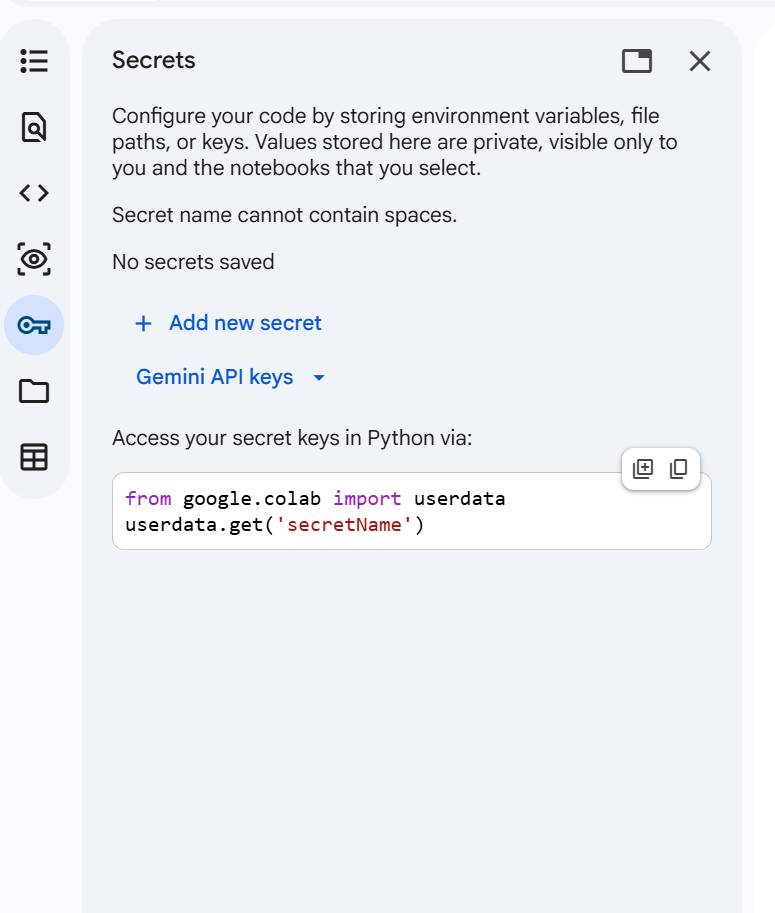

2. Then, click **+ Add new secret**. In the **Name** field, enter a name to identify the GitHub Personal Access Token, for example, **Gittoken**. In the **Value** field, paste the token. Once done, close the **Secrets** window. We will access this token programmatically later.

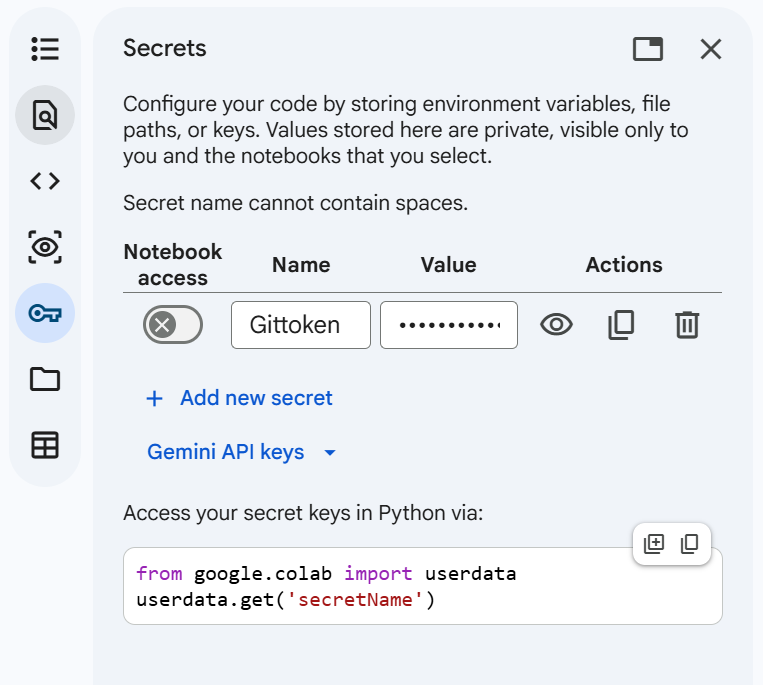

Once done, toggle the `Notebook access`

In [48]:
# Your GitHub Personal Access Token

from google.colab import userdata
GITHUB_TOKEN = userdata.get('git_token')  # Replace with the secret name. For example, Gittoken

# After executing this code, you may be prompted to grant access. Click **Grant Access** to continue.

The GitHub Personal Access Token is retrieved from Google Colab's secure secrets storage instead of being hardcoded. This keeps the token out of the notebook source code and out of version control.

1. **Define authentication and repository details:**
   - `GITHUB_TOKEN` stores the GitHub Personal Access Token for authentication.
   - `REPO_NAME` specifies the name of the new GitHub repository.

2. **Authenticate with GitHub:**
   - `g = Github(GITHUB_TOKEN)` creates a GitHub client using the token.
   - `user = g.get_user()` retrieves the authenticated user.

3. **Create the repository:**
   - `user.create_repo()` creates a new public repository on GitHub with an auto-generated README.

4. **Push files to the repository:**
   - `repo.create_file()` uploads each deployment file to the repository.
   - Backend files (`app.py`, `requirements.txt`, `Dockerfile`, model) go into the `backend/` folder.
   - Frontend files (`app.py`, `requirements.txt`, `Dockerfile`) go into the `frontend/` folder.
   - For the `.joblib` model file, which is binary, PyGithub handles the encoding automatically.

In [49]:
# Name for the repository
REPO_NAME = "novacrest-qna"

# Authenticate with GitHub
from github import Github
import os

g = Github(GITHUB_TOKEN)
user = g.get_user()

print(f"Authenticated as: {user.login}")


# ---------------------------------------------------------
# Get existing repository or create a new one
# ---------------------------------------------------------

try:
    # Check if repository already exists
    repo = user.get_repo(REPO_NAME)
    print(f"Repository already exists: {repo.html_url}")

except Exception:
    # Repository does not exist, so create it
    repo = user.create_repo(
        REPO_NAME,
        description="NovaCrest RAG",
        private=False,
        auto_init=True
    )

    print(f"Repository created successfully: {repo.html_url}")


# ---------------------------------------------------------
# Files to push
# ---------------------------------------------------------

files_to_push = {
    "backend/app.py": "backend_files/app.py",
    "backend/rag_utils.py": "backend_files/rag_utils.py",
    "backend/requirements.txt": "backend_files/requirements.txt",
    "backend/Dockerfile": "backend_files/Dockerfile",

    "frontend/app.py": "frontend_files/app.py",
    "frontend/requirements.txt": "frontend_files/requirements.txt",
    "frontend/Dockerfile": "frontend_files/Dockerfile",
}


# ---------------------------------------------------------
# Function to upload or update a file
# ---------------------------------------------------------

def upload_or_update_file(repo, repo_path, local_path):

    with open(local_path, "rb") as f:
        content = f.read()

    try:
        # Check if the file already exists
        existing_file = repo.get_contents(
            repo_path,
            ref="main"
        )

        # File exists -> update it
        repo.update_file(
            path=repo_path,
            message=f"Update {repo_path}",
            content=content,
            sha=existing_file.sha,
            branch="main"
        )

        print(f"Updated: {repo_path}")

    except Exception:
        # File does not exist -> create it
        repo.create_file(
            path=repo_path,
            message=f"Add {repo_path}",
            content=content,
            branch="main"
        )

        print(f"Uploaded: {repo_path}")


# ---------------------------------------------------------
# Upload / update individual files
# ---------------------------------------------------------

for repo_path, local_path in files_to_push.items():

    upload_or_update_file(
        repo,
        repo_path,
        local_path
    )

# ---------------------------------------------------------
# Upload / update FAISS index folder
# ---------------------------------------------------------

faiss_folder = "backend_files/faiss_index"

if os.path.exists(faiss_folder):

    for root, dirs, files in os.walk(faiss_folder):

        for file_name in files:

            # Full local path
            local_path = os.path.join(
                root,
                file_name
            )

            # Path relative to backend_files/
            relative_path = os.path.relpath(
                local_path,
                "backend_files"
            )

            # GitHub repository path
            repo_path = os.path.join(
                "backend",
                relative_path
            ).replace("\\", "/")

            upload_or_update_file(
                repo,
                repo_path,
                local_path
            )

else:
    print(
        f"Warning: FAISS folder not found: {faiss_folder}"
    )


print("\nAll files pushed successfully!")
print(f"Repository: {repo.html_url}")

Authenticated as: harishmathh
Repository created successfully: https://github.com/harishmathh/novacrest-qna
Uploaded: backend/app.py
Uploaded: backend/rag_utils.py
Uploaded: backend/requirements.txt
Uploaded: backend/Dockerfile
Uploaded: frontend/app.py
Uploaded: frontend/requirements.txt
Uploaded: frontend/Dockerfile
Uploaded: backend/faiss_index/index.pkl
Uploaded: backend/faiss_index/index.faiss

All files pushed successfully!
Repository: https://github.com/harishmathh/novacrest-qna


Once all the files have been pushed, the next step is to add the secrets (OpenAI API Key and OpenAI Base URL) to GitHub Codespaces so that the backend can connect to OpenAI. For this, refer to the document titled **"Adding Secrets to GitHub Codespaces."**

**Note:** The link to your GitHub repository will be displayed as the output of the previous cell.

Then, refer to the document titled **"Deploying Frontend and Backend on GitHub Codespaces"** for the next steps to deploy the Streamlit application and see it in action.

# Deployment - Inference

Before executing the code cells below, ensure the following:

1. GitHub Codespaces is up and running.

2. Both the frontend and backend applications are running in GitHub Codespaces, and the ports are set to **Public**.

3. The forwarded URL of the backend is copied.

In [ ]:
# Set the base URL for the deployed Flask API running in GitHub Codespaces
model_root_url = "https://laughing-space-winner-gr57wx6qxq43wpxr-7860.app.github.dev/"  # Replace with your Codespace forwarded URL for port 7860

Replace the URL above with the actual forwarded URL from your Codespace's Ports tab. It will look something like `https://organic-space-abcd1234-7860.app.github.dev`. Make sure there is no trailing slash at the end.

This URL is a tunnel that Codespaces creates to route external HTTP requests into your Codespace and to the Flask container running on port 7860.

In [ ]:
model_chunks_url = model_root_url + "/v1/relevant_chunks"  # Endpoint for getting relevant chunks

Since our model predictions are served through the Flask endpoint we created, we need to call this endpoint to get the relevant chunks.

> ```@app.post('/v1/relevant_chunks')```

In [ ]:
model_ans_chunks_url = model_root_url + "/v1/answer_with_relevant_chunks"  # Endpoint for getting the answer with relevant chunks

> ```@app.post('/v1/answer_with_relevant_chunks')```

The idea is to send a single request to the API and receive an immediate response. This is useful for real-time applications like recommendation systems and fraud detection.

* This data is sent as a JSON payload in a POST request to the model endpoint.
* The model processes the input features and returns a prediction as a JSON payload.

## Deployment - Inference (Relevant chunks)

In [ ]:
# Define the test payload with a sample query and number of chunks to retrieve
payload = {
  "query": "What Salesforce editions support Sales Cloud Einstein and what is the licensing model?",
  "k": 3,
}

In [ ]:
# Sending a POST request to the model endpoint with the test payload
response = requests.post(model_chunks_url, json=payload)

In [ ]:
# Check the HTTP status of the response
response

<Response [200]>

- The `<Response [200]>` you see is an HTTP status code.
- It indicates that your request was successful, and the server was able to process it without any problems.

In [ ]:
# Print the full JSON response containing the retrieved chunks
print(response.json())

{'k': 3, 'query': 'What Salesforce editions support Sales Cloud Einstein and what is the licensing model?', 'relevant_chunks': ["Content:\n## REQUIRED EDITIONS\n\nAvailable in: Lightning Experience and Salesforce Classic\n\nAvailable with Sales Cloud Einstein, which is available in Performance and Unlimited Editions, and for an extra cost in Enterprise Edition\n\n## General Considerations\n\n- Sales Cloud Einstein is available only to users with standard Salesforce licenses.\n- Sales Cloud Einstein isn't supported in Government Cloud and Government Cloud Plus organizations. Turning on Sales Cloud Einstein can send data outside the authorization boundary. Contact your Salesforce account executive for more details.\n- When you set up Sales Cloud Einstein, Salesforce installs two packages in your org, SalesforceIQ Cloud and Sales Insights. Each package adds an associated integration user and profile. Salesforce uses these entities to provide insights to your org. If you update these entit

- The JSON output contains the original query, the value of k, and a list of the top-k retrieved chunks.
- Each chunk includes the text content and metadata showing which source document it came from.
- This confirms the retrieval endpoint is working correctly on the deployed backend.

## Deployment - Inference (Answer with relevant chunks)

In [ ]:
# Define the test payload with query and full model parameters for the answer endpoint
payload = {
"query": "What Salesforce editions support Sales Cloud Einstein and what is the licensing model?",
"k": 3,
"model_name": "gpt-4o-mini",
"temperature": 0.0,
"top_p": 1.0,
"max_tokens": 512
}

**Note:** The below code snippet may take some time to execute, typically between 1 to 3 minutes.

In [ ]:
# Sending a POST request to the model endpoint with the test payload
response = requests.post(model_ans_chunks_url, json=payload)

In [ ]:
# Check the HTTP status of the response
response

<Response [200]>

- The `<Response [200]>` you see is an HTTP status code.
- It indicates that your request was successful, and the server was able to process it without any problems.

In [ ]:
# Print the full JSON response containing the answer and supporting chunks
print(response.json())

{'answer': 'Sales Cloud Einstein is supported in the following Salesforce editions:\n\n- **Performance Edition**\n- **Unlimited Edition**\n- **Enterprise Edition** (available for an extra cost)\n\nSales Cloud Einstein is available in both Lightning Experience and Salesforce Classic. It is important to note that it is only available to users with standard Salesforce licenses and is not supported in Government Cloud and Government Cloud Plus organizations.\n\nFor licensing, Sales Cloud Einstein is included in the Sales Cloud Unlimited Edition, while it requires an additional cost in the Enterprise Edition.', 'k': 3, 'max_tokens': 512, 'model_name': 'gpt-4o-mini', 'query': 'What Salesforce editions support Sales Cloud Einstein and what is the licensing model?', 'relevant_chunks': ["Content:\n## REQUIRED EDITIONS\n\nAvailable in: Lightning Experience and Salesforce Classic\n\nAvailable with Sales Cloud Einstein, which is available in Performance and Unlimited Editions, and for an extra cos

- The JSON response now includes both the generated answer and the relevant chunks that were used to produce it.
- This is the same payload the Streamlit frontend receives when the user selects "Answer + Relevant Chunks" mode.
- Having both the answer and its supporting evidence in a single response makes it easy for hotel staff to verify the information before sharing it with guests.

**IMPORTANT:** Once the previous cell has been executed and the application is no longer required, please refer to the document titled **"Deleting Codespace"** to delete the Codespace, as it may continue to consume resources.

# Business Insights and Recommendations

## Business Insights

- Docling's table extraction preserved edition comparison grids, permission matrices, and CXI KPI calculation tables in structured markdown format. A large portion of the Salesforce documentation is table-heavy, and queries like "What editions support Einstein Lead Scoring?" or "What permissions are needed for CXI setup?" have their answers sitting inside table rows. Without this structured extraction, those answers would have been lost to flat text parsing and the retrieval step would have had no usable content to return.

- The retrieval test confirmed that a general-purpose embedding model (BAAI/bge-base-en-v1.5) combined with 512-token chunks and 50-token overlap is able to pull the correct document sections for Salesforce-specific queries. The chunking separator hierarchy (paragraph, line break, heading, sentence) kept edition details and setup steps together within single chunks rather than splitting them across boundaries, which directly contributed to the retrieval quality seen in evaluation.

- On the test set, approximately 30% of queries were auto-answered, and the system correctly returned the fallback response for out-of-scope and unanswerable queries (e.g., social media channel support, ROI estimation). This shows the faithfulness rules in the prompt and the composite score routing are working together. The system is not letting low-confidence answers through, which is the right behavior for this use case.

## Business Recommendations

- Start tracking which queries consistently fall into the "manual lookup" bucket. Those patterns will tell you exactly which documentation areas have gaps in the knowledge base or where the guides need to be restructured for better retrieval. Over time, feeding that back into the document design will push more queries into the auto answer tier.

- As NovaCrest adopts new Salesforce capabilities (Einstein Generative AI, Data Cloud integrations, new CRM Analytics dashboards), the documentation library will grow. Build a lightweight pipeline now for ingesting new or updated Salesforce documents into the vector store without rebuilding the whole index from scratch. Otherwise, keeping the system current will become a bottleneck.

- Consider adding a short feedback loop where users can flag wrong or incomplete answers with one click. Right now, evaluation relies on a fixed test set scored by an LLM judge, which is useful but static. Real world feedback from the people actually using it daily will surface edge cases and failure modes that no pre-built test set can anticipate.